In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Create project folders
Path("data").mkdir(exist_ok=True)
Path("reports").mkdir(exist_ok=True)
Path("images").mkdir(exist_ok=True)

print("Sales Analysis Project")
print("Project folders created successfully.")
print("Ready to analyze sales data!")

Sales Analysis Project
Project folders created successfully.
Ready to analyze sales data!


In [2]:

import pandas as pd
from pathlib import Path

sales = [
    ["2026-01-03", "Laptop", "Electronics", 2, 65000, 52000],
    ["2026-01-05", "Mouse", "Accessories", 10, 1200, 700],
    ["2026-01-08", "Keyboard", "Accessories", 5, 2500, 1500],
    ["2026-01-12", "Phone", "Electronics", 3, 35000, 29000],
    ["2026-01-15", "Desk", "Furniture", 2, 18000, 13000],
    ["2026-01-19", "Chair", "Furniture", 4, 8500, 6000],
    ["2026-02-02", "Laptop", "Electronics", 3, 65000, 52000],
    ["2026-02-06", "Mouse", "Accessories", 15, 1200, 700],
    ["2026-02-10", "Phone", "Electronics", 4, 35000, 29000],
    ["2026-02-14", "Keyboard", "Accessories", 8, 2500, 1500],
    ["2026-02-18", "Chair", "Furniture", 3, 8500, 6000],
    ["2026-02-22", "Desk", "Furniture", 1, 18000, 13000],
    ["2026-03-01", "Laptop", "Electronics", 4, 65000, 52000],
    ["2026-03-04", "Phone", "Electronics", 2, 35000, 29000],
    ["2026-03-09", "Mouse", "Accessories", 12, 1200, 700],
    ["2026-03-13", "Keyboard", "Accessories", 6, 2500, 1500],
    ["2026-03-17", "Desk", "Furniture", 3, 18000, 13000],
    ["2026-03-21", "Chair", "Furniture", 5, 8500, 6000],
    ["2026-03-24", "Laptop", "Electronics", 1, 65000, 52000],
    ["2026-03-28", "Phone", "Electronics", 5, 35000, 29000]
]

df = pd.DataFrame(
    sales,
    columns=[
        "date", "product", "category",
        "quantity", "unit_price", "unit_cost"
    ]
)

df["date"] = pd.to_datetime(df["date"])
df["revenue"] = df["quantity"] * df["unit_price"]
df["total_cost"] = df["quantity"] * df["unit_cost"]
df["profit"] = df["revenue"] - df["total_cost"]

df.to_csv("data/sales_data.csv", index=False)

print("Dataset created successfully!")
print("Number of sales records:", len(df))
display(df.head(10))


Dataset created successfully!
Number of sales records: 20


,date,product,category,quantity,unit_price,unit_cost,revenue,total_cost,profit
0,2026-01-03,Laptop,Electronics,2,65000,52000,130000,104000,26000
1,2026-01-05,Mouse,Accessories,10,1200,700,12000,7000,5000
2,2026-01-08,Keyboard,Accessories,5,2500,1500,12500,7500,5000
3,2026-01-12,Phone,Electronics,3,35000,29000,105000,87000,18000
4,2026-01-15,Desk,Furniture,2,18000,13000,36000,26000,10000
5,2026-01-19,Chair,Furniture,4,8500,6000,34000,24000,10000
6,2026-02-02,Laptop,Electronics,3,65000,52000,195000,156000,39000
7,2026-02-06,Mouse,Accessories,15,1200,700,18000,10500,7500
8,2026-02-10,Phone,Electronics,4,35000,29000,140000,116000,24000
9,2026-02-14,Keyboard,Accessories,8,2500,1500,20000,12000,8000


In [3]:

print("Dataset shape:", df.shape)
print("\nColumn information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nTotal revenue: KSh", f"{df['revenue'].sum():,.2f}")
print("Total profit: KSh", f"{df['profit'].sum():,.2f}")


Dataset shape: (20, 9)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date        20 non-null     datetime64[ns]
 1   product     20 non-null     object        
 2   category    20 non-null     object        
 3   quantity    20 non-null     int64         
 4   unit_price  20 non-null     int64         
 5   unit_cost   20 non-null     int64         
 6   revenue     20 non-null     int64         
 7   total_cost  20 non-null     int64         
 8   profit      20 non-null     int64         
dtypes: datetime64[ns](1), int64(6), object(2)
memory usage: 1.5+ KB

Missing values:
date          0
product       0
category      0
quantity      0
unit_price    0
unit_cost     0
revenue       0
total_cost    0
profit        0
dtype: int64

Total revenue: KSh 1,441,900.00
Total profit: KSh 311,500.00


In [4]:

# 1. Performance by product
product_summary = (
    df.groupby("product")
    .agg(
        units_sold=("quantity", "sum"),
        revenue=("revenue", "sum"),
        profit=("profit", "sum")
    )
    .sort_values("revenue", ascending=False)
)

print("PRODUCT PERFORMANCE")
display(product_summary)

# 2. Performance by category
category_summary = (
    df.groupby("category")
    .agg(
        revenue=("revenue", "sum"),
        profit=("profit", "sum")
    )
    .sort_values("revenue", ascending=False)
)

print("CATEGORY PERFORMANCE")
display(category_summary)

# 3. Monthly performance
df["month"] = df["date"].dt.to_period("M").astype(str)

monthly_summary = (
    df.groupby("month")
    .agg(
        revenue=("revenue", "sum"),
        profit=("profit", "sum")
    )
    .sort_index()
)

print("MONTHLY PERFORMANCE")
display(monthly_summary)

# 4. Overall profit margin
total_revenue = df["revenue"].sum()
total_profit = df["profit"].sum()

print(f"Overall revenue: KSh {total_revenue:,.2f}")
print(f"Overall profit: KSh {total_profit:,.2f}")
print(f"Overall profit margin: {total_profit / total_revenue:.2%}")


PRODUCT PERFORMANCE


,units_sold,revenue,profit
product,,,
Laptop,10,650000,130000
Phone,14,490000,84000
Desk,6,108000,30000
Chair,12,102000,30000
Keyboard,19,47500,19000
Mouse,37,44400,18500


CATEGORY PERFORMANCE


,revenue,profit
category,,
Electronics,1140000,214000
Furniture,210000,60000
Accessories,91900,37500


MONTHLY PERFORMANCE


,revenue,profit
month,,
2026-01,329500,74000
2026-02,416500,91000
2026-03,695900,146500


Overall revenue: KSh 1,441,900.00
Overall profit: KSh 311,500.00
Overall profit margin: 21.60%


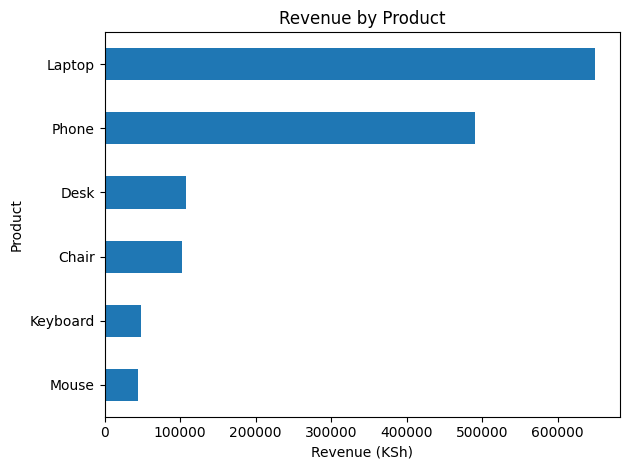

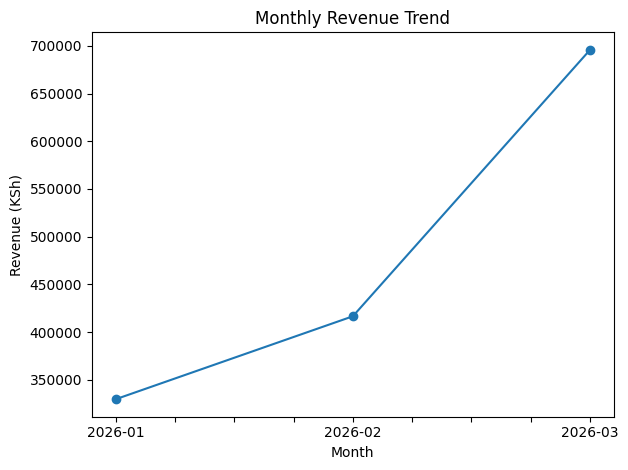

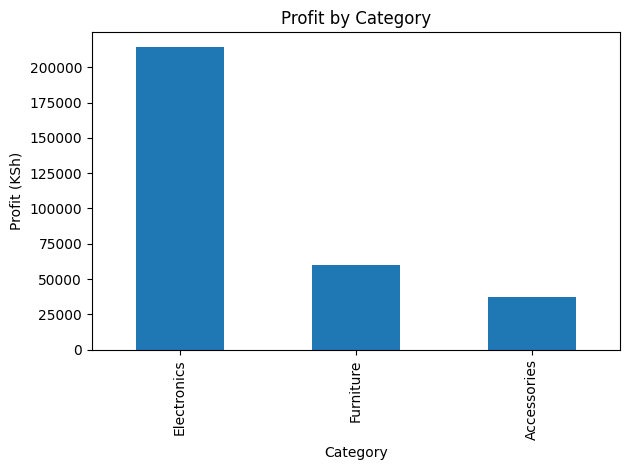

In [5]:

# Revenue by product
product_summary["revenue"].sort_values().plot(
    kind="barh",
    title="Revenue by Product",
    xlabel="Revenue (KSh)",
    ylabel="Product"
)
plt.tight_layout()
plt.savefig("images/revenue_by_product.png", dpi=150)
plt.show()

# Monthly revenue trend
monthly_summary["revenue"].plot(
    kind="line",
    marker="o",
    title="Monthly Revenue Trend",
    xlabel="Month",
    ylabel="Revenue (KSh)"
)
plt.tight_layout()
plt.savefig("images/monthly_revenue_trend.png", dpi=150)
plt.show()

# Profit by category
category_summary["profit"].plot(
    kind="bar",
    title="Profit by Category",
    xlabel="Category",
    ylabel="Profit (KSh)"
)
plt.tight_layout()
plt.savefig("images/profit_by_category.png", dpi=150)
plt.show()


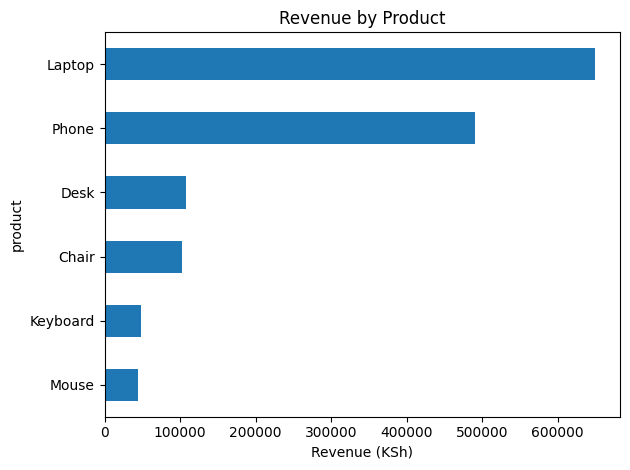

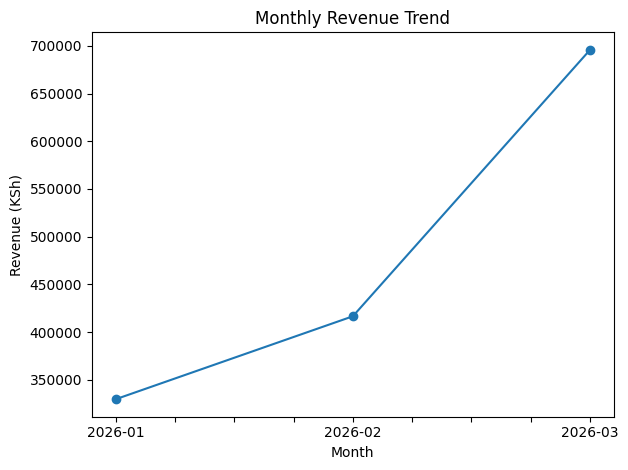

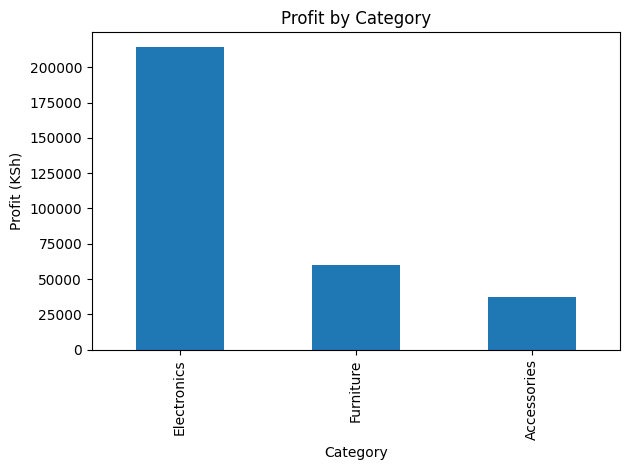

Reports and charts saved successfully!
Files created:
reports/category_summary.csv
reports/monthly_summary.csv
reports/product_summary.csv
images/monthly_revenue_trend.png
images/profit_by_category.png
images/revenue_by_product.png


In [6]:

from pathlib import Path
import matplotlib.pyplot as plt

Path("reports").mkdir(exist_ok=True)
Path("images").mkdir(exist_ok=True)

# Export analysis tables
product_summary.to_csv("reports/product_summary.csv")
category_summary.to_csv("reports/category_summary.csv")
monthly_summary.to_csv("reports/monthly_summary.csv")

# Chart 1: Revenue by product
product_summary["revenue"].sort_values().plot(
    kind="barh", title="Revenue by Product",
    xlabel="Revenue (KSh)"
)
plt.tight_layout()
plt.savefig("images/revenue_by_product.png", dpi=150)
plt.show()
plt.close()

# Chart 2: Monthly revenue trend
monthly_summary["revenue"].plot(
    kind="line", marker="o",
    title="Monthly Revenue Trend",
    xlabel="Month", ylabel="Revenue (KSh)"
)
plt.tight_layout()
plt.savefig("images/monthly_revenue_trend.png", dpi=150)
plt.show()
plt.close()

# Chart 3: Profit by category
category_summary["profit"].plot(
    kind="bar", title="Profit by Category",
    xlabel="Category", ylabel="Profit (KSh)"
)
plt.tight_layout()
plt.savefig("images/profit_by_category.png", dpi=150)
plt.show()
plt.close()

print("Reports and charts saved successfully!")
print("Files created:")
for folder in ["reports", "images"]:
    for file in sorted(Path(folder).glob("*")):
        print(file)


In [7]:

from pathlib import Path
import zipfile

readme = """
# Sales Data Analysis with Python

## Project Overview
This project analyzes a simulated retail sales dataset using Python,
pandas, and Matplotlib. It explores product performance, category
revenue, monthly trends, and profitability.

## Objectives
- Calculate revenue, costs, and profit.
- Identify top-performing products.
- Compare sales across product categories.
- Analyze monthly revenue and profit trends.
- Present findings using visualizations.

## Tools
- Python
- pandas
- Matplotlib
- Google Colab

## Key Findings
- Total revenue: KSh 1,441,900
- Total profit: KSh 311,500
- Overall profit margin: 21.60%
- Electronics generated KSh 1,140,000 in revenue.
- Laptops generated the highest product revenue at KSh 650,000.
- March 2026 recorded the highest monthly revenue at KSh 695,900.
- Mouse had the highest unit sales, with 37 units sold.

## Visualizations

### Revenue by Product
![Revenue by Product](images/revenue_by_product.png)

### Monthly Revenue Trend
![Monthly Revenue Trend](images/monthly_revenue_trend.png)

### Profit by Category
![Profit by Category](images/profit_by_category.png)

## Project Structure
- `data/sales_data.csv`: Original simulated sales dataset
- `reports/product_summary.csv`: Product performance
- `reports/category_summary.csv`: Category performance
- `reports/monthly_summary.csv`: Monthly performance
- `images/`: Generated charts
- `sales_analysis.ipynb`: Analysis notebook

## Limitations
The dataset is simulated and contains only 20 records from
January to March 2026. The findings are illustrative and should
not be interpreted as evidence about a real business.

## Author
Shirleen Munene
"""

Path("README.md").write_text(readme.strip() + "\n", encoding="utf-8")

# Package project files
with zipfile.ZipFile(
    "sales-data-analysis.zip", "w", zipfile.ZIP_DEFLATED
) as archive:
    for folder in ["data", "reports", "images"]:
        for file in Path(folder).rglob("*"):
            if file.is_file():
                archive.write(file, file.as_posix())
    archive.write("README.md", "README.md")

print("README created.")
print("Project ZIP created.")
print("Check that these files exist:")
for name in [
    "data/sales_data.csv",
    "reports/product_summary.csv",
    "reports/category_summary.csv",
    "reports/monthly_summary.csv",
    "images/revenue_by_product.png",
    "images/monthly_revenue_trend.png",
    "images/profit_by_category.png",
    "README.md",
    "sales-data-analysis.zip"
]:
    print(f"{'OK' if Path(name).exists() else 'MISSING'}: {name}")


README created.
Project ZIP created.
Check that these files exist:
OK: data/sales_data.csv
OK: reports/product_summary.csv
OK: reports/category_summary.csv
OK: reports/monthly_summary.csv
OK: images/revenue_by_product.png
OK: images/monthly_revenue_trend.png
OK: images/profit_by_category.png
OK: README.md
OK: sales-data-analysis.zip


In [8]:
from google.colab import files
files.download("sales-data-analysis.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>